# Titanic Survival Prediction Using Machine Learning

## Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression

## Loading Data

In [18]:
test_df = pd.read_csv('../data/test.csv')
train_df = pd.read_csv('../data/train.csv')

## EDA (Exploratory Data Analysis)

In [122]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [123]:
len(train_df["PassengerId"].unique()) 
# testen, ob bestimmte Gruppen unique sind und wie wiele Ausprägungen der Werte es dort gibt

891

In [124]:
train_df["Sex"].unique()

<StringArray>
['male', 'female']
Length: 2, dtype: str

PassengerId - ID einer bestimmten Person (unique)

Survived - Überlebt (Ja oder Nein -- 1 oder 0)

Pclass - sozialer Status der Passagiere (1: Oberschicht -- 2: Mittelschicht -- 3: Unterschicht)

Name - Name einer Person

Sex	- Geschlecht einer Person

Age	- Alter einer Person

SibSp - Anzahl der Geschwister oder Ehepatner, die ebenfalls an Bord des Schiffe waren

Parch - Anzahl der Eltern oder Kinder mit denen eine Person gereist ist

Ticket - Personen die z.B. als Familie zusammen reisen, haben gemeinsam eine Ticketnummer (nicht unique)

Fare - Ticketpreis, den ein Passagier für seine Überfahrt bezahlt hat

Cabin - Kabinennummer

Embarked - Zustiegsort der Passagiere

In [125]:
train_df.info() # Problem mit NULL-Werten

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [126]:
train_df.isnull().sum() # wie viele NULL-Werte wo auftauchen

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [127]:
eda_train_num = train_df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]] 
# alle Zahlenwerte werden betrachtet (es fällt PassengerId weg, da sie keinen releventen 
# Einflussfaktor darstellt, da diese höchstwahrscheinlich einzigartig ist)
eda_train_str = train_df[["Sex", "Ticket", "Cabin", "Embarked"]] 
# alle als String hinterlegten Werte (der Name fällt, weg, da er eher uninteressant ist)

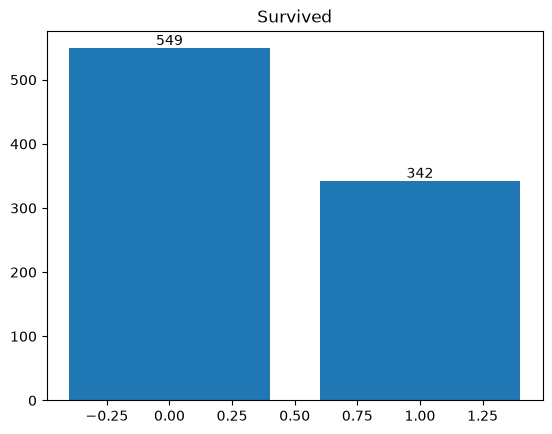

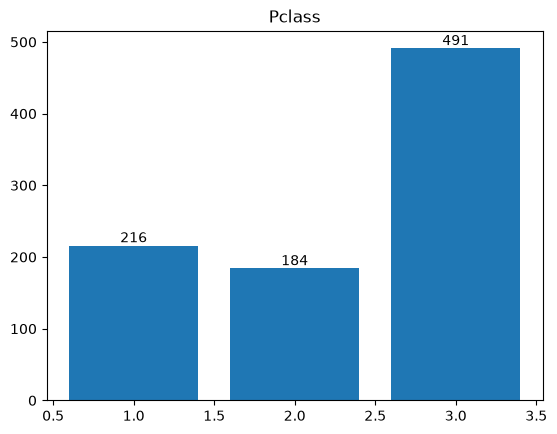

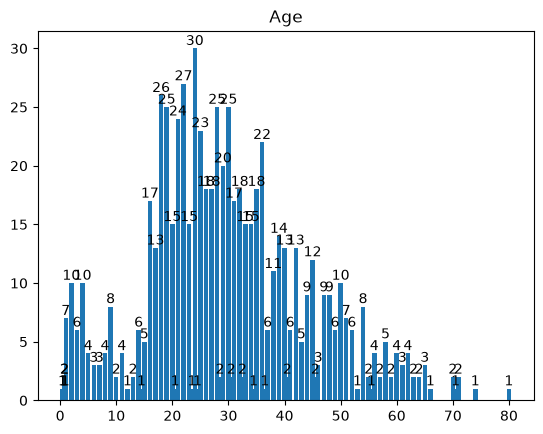

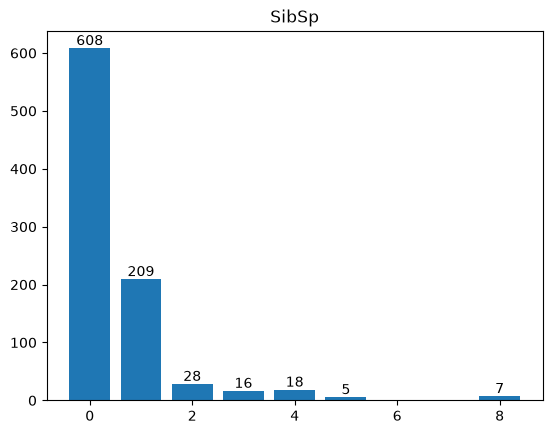

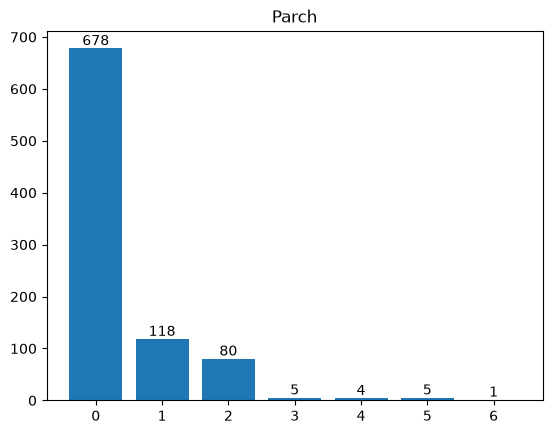

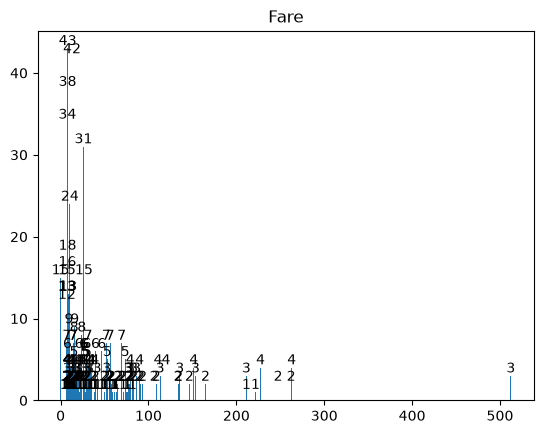

In [128]:
 for i in eda_train_num:
    counts = train_df[i].value_counts()

    plt.bar(counts.index, counts.values)
    plt.title(i)
    plt.bar_label(plt.gca().containers[0], fmt = "%.0f")
    plt.show()

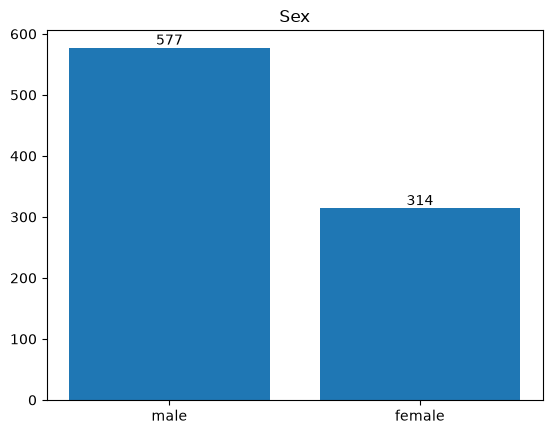

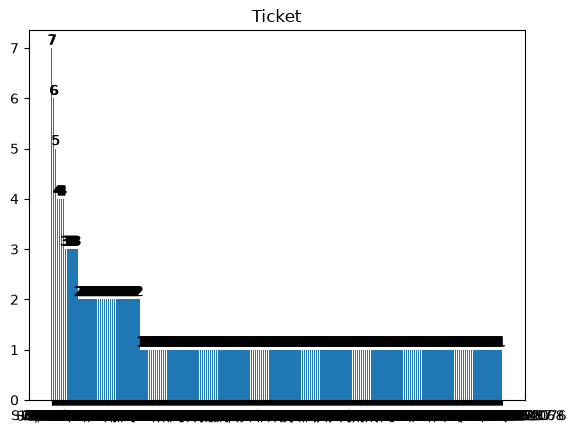

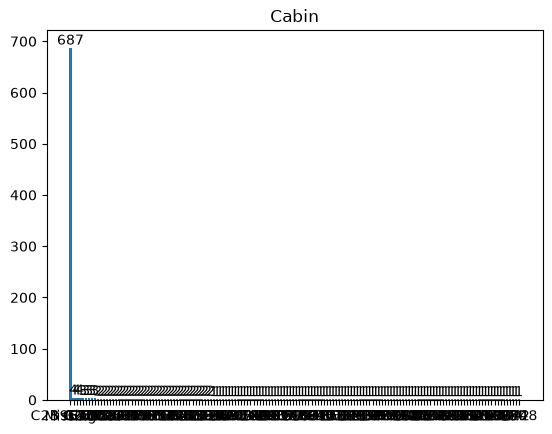

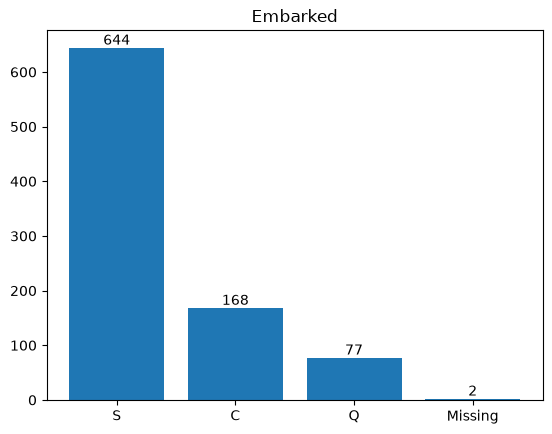

In [129]:
for i in eda_train_str:
    counts = train_df[i].fillna("Missing").value_counts()

    plt.bar(counts.index, counts.values)
    plt.title(i)
    plt.bar_label(plt.gca().containers[0], fmt = "%.0f")
    plt.show()

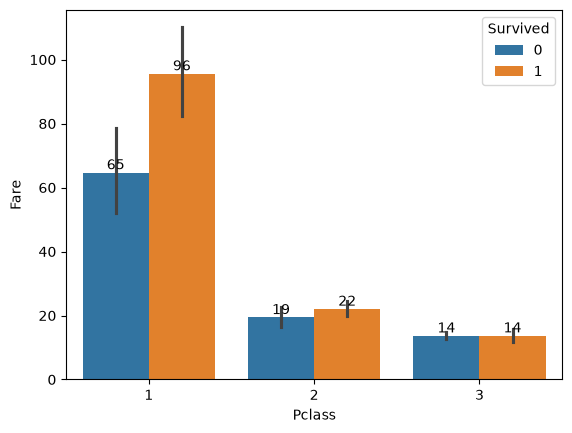

In [130]:
ax = sns.barplot(data = train_df, x = "Pclass", y = "Fare", hue = "Survived")

for container in ax.containers:
    ax.bar_label(container, fmt = "%.0f")

plt.show()
# hat die Ticketklasse einen Einfluss auf die Überlebenschance des Passagiers

In [131]:
pd.pivot_table(
    train_df,
    index = "Survived",
    values = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
)
# Vergleich von Werten bei überlebenden und nicht überlebenden Passagieren 
# (wie alt waren die Personen im Durchschnitt überlebten oder nicht überlebten etc.)

,Age,Fare,Parch,Pclass,SibSp
Survived,,,,,
0,30.626179,22.117887,0.329690,2.531876,0.553734
1,28.343690,48.395408,0.464912,1.950292,0.473684


In [132]:
pd.pivot_table(
    train_df,
    index = "Survived",
    columns = "Sex",
    values = "PassengerId",
    aggfunc = "count"
)
# wie männliche oder weibliche Passagiere haben überlebt oder sind gestorben

Sex,female,male
Survived,,
0,81,468
1,233,109


In [133]:
pd.pivot_table(
    train_df,
    index = "Survived",
    columns = "Ticket",
    values = "PassengerId",
    aggfunc = "count"
)
# wie viele Personen, die sich ein Ticket geteilt haben (z.B. Familie) sind gestorben oder haben überlebt

Ticket,110152,110413,110465,110564,110813,111240,111320,111361,111369,111426,...,STON/O2. 3101290,SW/PP 751,W./C. 14258,W./C. 14263,W./C. 6607,W./C. 6608,W./C. 6609,W.E.P. 5734,W/C 14208,WE/P 5735
Survived,,,,,,,,,,,,,,,,,,,,,
0,NaN,1.0,2.0,NaN,NaN,1.0,1.0,NaN,NaN,NaN,...,1.0,NaN,NaN,1.0,2.0,4.0,1.0,1.0,1.0,1.0
1,3.0,2.0,NaN,1.0,1.0,NaN,NaN,2.0,1.0,1.0,...,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0


In [134]:
pd.pivot_table(
    train_df,
    index = "Survived",
    columns = "Cabin",
    values = "PassengerId",
    aggfunc = "count"
)
# wie viele Passagiere aus bestimmten Kabinen haben überlebt oder sind gestorben

Cabin,A10,A14,A16,A19,A20,A23,A24,A26,A31,A32,...,E8,F E69,F G63,F G73,F2,F33,F38,F4,G6,T
Survived,,,,,,,,,,,,,,,,,,,,,
0,1.0,1.0,NaN,1.0,NaN,NaN,1.0,NaN,NaN,1.0,...,NaN,NaN,1.0,2.0,1.0,NaN,1.0,NaN,2.0,1.0
1,NaN,NaN,1.0,NaN,1.0,1.0,NaN,1.0,1.0,NaN,...,2.0,1.0,NaN,NaN,2.0,3.0,NaN,2.0,2.0,NaN


In [135]:
pd.pivot_table(
    train_df,
    index = "Survived",
    columns = "Embarked",
    values = "PassengerId",
    aggfunc = "count"
)
# wie viele Passagiere sind je nach dem Ort an dem sie zugestiegen sind gestorben oder haben überlebt

Embarked,C,Q,S
Survived,,,
0,75,47,427
1,93,30,217


## Data Cleaning

In [153]:
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [149]:
train_df_cleaned = train_df.copy()

train_df_cleaned = train_df_cleaned.drop(columns = ["PassengerId", "Cabin", "Name", "Ticket"])
# PassengerId und Name fallen raus, die sie nicht sinnvoll verwenden kann - für Cabin und Ticket als 
# String fällt mir gerade noch keine Verwendung ein

train_df_cleaned["Age"] = train_df_cleaned["Age"].fillna(train_df_cleaned["Age"].mean())
# da wo das Alter leer ist, soll es durch den Durchschnitt ersetzt werden, damit man diese NULL-Spalten 
# nicht aussortieren muss

train_df_cleaned["Embarked"] = train_df_cleaned["Embarked"].fillna(train_df_cleaned["Embarked"].mode()[0])
# für die Datenpunkte ohne Embarkment den Zustiegsort nehmen, der am häufigsten vorkommt

In [150]:
# train_df_cleaned.to_csv("train_df_cleaned.csv", index = False)
# erstmal auskommentiert, damit nicht ausversehen weitere csv-Dateien erstellt werden

In [152]:
train_df_cleaned.isnull().sum()
# keine NULL-Werte mehr

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

## Working with the Features

<Axes: >

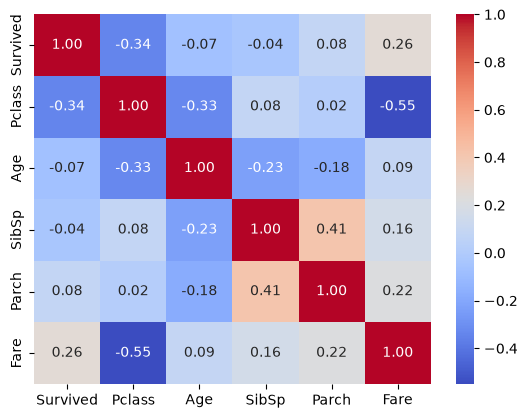

In [5]:
train_df_cleaned = pd.read_csv('../data/train_df_cleaned.csv')

corr = train_df_cleaned.corr(numeric_only = True)
sns.heatmap(corr, annot = True, fmt = ".2f", cmap = "coolwarm")
# stellt die Korrelation zwischen den einzelnen Merkmalen dar

In [6]:
cols = ["Sex", "Embarked"]
le = LabelEncoder()
for col in cols:
    train_df_cleaned[col] = le.fit_transform(train_df_cleaned[col])

train_df_cleaned
# mit Hilfe dieser Funktion werden alle Werte (hier Sex und Embarked), 
# die noch als String vorliegen in Integer umgewandelt
# dies ist für die Arbeit mit Machine Learning Modellen hilfreich

# Sex: male = 1, female = 0
# Embarked: S = 2, Q = 1, C = 0

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.000000,1,0,7.2500,2
1,1,1,0,38.000000,1,0,71.2833,0
2,1,3,0,26.000000,0,0,7.9250,2
3,1,1,0,35.000000,1,0,53.1000,2
4,0,3,1,35.000000,0,0,8.0500,2
...,...,...,...,...,...,...,...,...
886,0,2,1,27.000000,0,0,13.0000,2
887,1,1,0,19.000000,0,0,30.0000,2
888,0,3,0,29.699118,1,2,23.4500,2
889,1,1,1,26.000000,0,0,30.0000,0


In [7]:
train_df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    int64  
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 55.8 KB


In [8]:
X = train_df_cleaned.drop("Survived", axis = 1)
y = train_df_cleaned["Survived"]
train_df_cleaned
# anhand von X soll das Modell lernen, ob ein Passagier überlebt hat, daher wird dort diese Spalte entfernt

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.000000,1,0,7.2500,2
1,1,1,0,38.000000,1,0,71.2833,0
2,1,3,0,26.000000,0,0,7.9250,2
3,1,1,0,35.000000,1,0,53.1000,2
4,0,3,1,35.000000,0,0,8.0500,2
...,...,...,...,...,...,...,...,...
886,0,2,1,27.000000,0,0,13.0000,2
887,1,1,0,19.000000,0,0,30.0000,2
888,0,3,0,29.699118,1,2,23.4500,2
889,1,1,1,26.000000,0,0,30.0000,0


## Setting up the Parameters for the Model

In [9]:
def classify(model):
    x_train, x_test, y_train, y_test = train_test_split(
        X, y, test_size = 0.25, random_state = 40
    )
    model.fit(x_train, y_train)
    print("Accuracy :", model.score(x_test, y_test))

    score = cross_val_score(model, X, y, cv = 5)
    print("CV Score :", np.mean(score))

# Daten in train und test Daten aufteilen
# 25% der Daten werden fürs Testen verwendet, 75% fürs Trainieren
# bei model.fit lernt das Modell nun anhand der Trainigsdaten Zusammenhänge 
# zwischen den Markmalen und dem Überleben

In [10]:
model = DecisionTreeClassifier()
classify(model)
# erster Ansatz für bestimmte Vorhersagen

Accuracy : 0.7713004484304933
CV Score : 0.7677044755508129


In [11]:
model = LGBMClassifier()
classify(model)
# zweiter Ansatz für bestimmte Vorhersagen

[LightGBM] [Info] Number of positive: 247, number of negative: 421
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000321 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 192
[LightGBM] [Info] Number of data points in the train set: 668, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.369760 -> initscore=-0.533244
[LightGBM] [Info] Start training from score -0.533244
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [12]:
model = XGBClassifier()
classify(model)
# weitere Ansätze

Accuracy : 0.7937219730941704
CV Score : 0.8159751428033394


In [13]:
model = RandomForestClassifier()
classify(model)
# weitere Ansätze

Accuracy : 0.7982062780269058
CV Score : 0.8103508882053857


In [14]:
model = ExtraTreesClassifier()
classify(model)
# weitere Ansätze

Accuracy : 0.8026905829596412
CV Score : 0.7991400414286611


In [15]:
model = LogisticRegression(max_iter = 1000)
classify(model)
# weitere Ansätze

Accuracy : 0.8071748878923767
CV Score : 0.786761659657272


In [16]:
model = XGBClassifier()
model.fit(X, y)
# trainiern des Klassifikationsmodells

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Preprocessing of the test-Dataset

In [19]:
test_df.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [20]:
test_df_cleaned = test_df.copy()

test_df_cleaned = test_df_cleaned.drop(columns = ["PassengerId", "Cabin", "Name", "Ticket"])
# PassengerId und Name fallen raus, die sie nicht sinnvoll verwenden kann - für Cabin und Ticket als 
# String fällt mir gerade noch keine Verwendung ein

test_df_cleaned["Age"] = test_df_cleaned["Age"].fillna(test_df_cleaned["Age"].mean())
# da wo das Alter leer ist, soll es durch den Durchschnitt ersetzt werden, damit man diese NULL-Spalten 
# nicht aussortieren muss

test_df_cleaned["Fare"] = test_df_cleaned["Fare"].fillna(test_df_cleaned["Fare"].mean)
# für die Datenpunkte ohne Embarkment den Zustiegsort nehmen, der am häufigsten vorkommt

In [21]:
# test_df_cleaned.to_csv("test_df_cleaned.csv", index = False)
# erstmal auskommentiert, damit nicht ausversehen weitere csv-Dateien erstellt werden

In [22]:
test_df_cleaned.isnull().sum()
# keine NULL-Werte mehr

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [23]:
cols = ["Sex", "Embarked"]
le = LabelEncoder()
for col in cols:
    test_df_cleaned[col] = le.fit_transform(test_df_cleaned[col])

test_df_cleaned
# mit Hilfe dieser Funktion werden alle Werte (hier Sex und Embarked), 
# die noch als String vorliegen in Integer umgewandelt
# dies ist für die Arbeit mit Machine Learning Modellen hilfreich

# Sex: male = 1, female = 0
# Embarked: S = 2, Q = 1, C = 0

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,34.50000,0,0,7.8292,1
1,3,0,47.00000,1,0,7.0,2
2,2,1,62.00000,0,0,9.6875,1
3,3,1,27.00000,0,0,8.6625,2
4,3,0,22.00000,1,1,12.2875,2
...,...,...,...,...,...,...,...
413,3,1,30.27259,0,0,8.05,2
414,1,0,39.00000,0,0,108.9,0
415,3,1,38.50000,0,0,7.25,2
416,3,1,30.27259,0,0,8.05,2


## Model Testing

In [24]:
print(test_df_cleaned["Fare"].dtype)
print(test_df_cleaned["Fare"].head())
# Problem, da oject Datentypen nicht verarbeitet werden können

object
0     7.8292
1        7.0
2     9.6875
3     8.6625
4    12.2875
Name: Fare, dtype: object


In [25]:
test_df_cleaned["Fare"] = pd.to_numeric(
    test_df_cleaned["Fare"], errors="coerce"
)
# daher muss dieser Datentyp umgewandelt werden

In [26]:
print(test_df_cleaned["Fare"].dtype)
print(test_df_cleaned["Fare"].isna().sum())
# prüfen, ob dabei fehlende Werte entstanden sind

float64
1


In [27]:
test_df_cleaned["Fare"] = test_df_cleaned["Fare"].fillna(
    test_df_cleaned["Fare"].median()
)
# diese fehlenden Werte durch den Median auffüllen

In [28]:
print(test_df_cleaned["Fare"].dtype)
print(test_df_cleaned["Fare"].isna().sum())
# und abschließend nochmal testen

float64
0


In [29]:
pred = model.predict(test_df_cleaned)
pred
# Verhersage anhend der test.csv, welche Passagiere überleben oder nicht überleben werden

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

In [30]:
submit = pd.read_csv('../data/gender_submission.csv')
submit
# die Beispiel CSV laden, um dort dann die Survived-Spalte durch die Werte, die 
# zurvor vorhergesagt wurden, zu ersetzen

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [31]:
submit["Survived"] = pred
submit
# ersetzen der Servived-Werte

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [32]:
submit.info()
# die Werte die es gibt nochmal begutachten, falls es dort Probleme bei dem Datentyp oder ähnlichem gibt

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB


In [33]:
# submit.to_csv("submission.csv", index = False)
# Abgabe CSV 